# Example: Does a Wolfram Market's Price Look Real?
In this example, we measure the stylized facts of the dealer's price in a Wolfram market and compare them with a real ticker and with the Farmer–Joshi market from L12a. The Wolfram market was built to study rule switches, not price statistics, and we ask what its price gets right and what it does not.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Measure the stylized facts of a model price:__ Compute the growth rates of the dealer's price in a Wolfram market that never switches rules, and measure their tails and autocorrelations.
> * __Compare a model with real prices:__ Put the Wolfram market's statistics beside those of a real ticker and the Farmer–Joshi market, and say which stylized facts each one shows.
> * __Test what feedback changes:__ Compare active, held, and random edge traders and a deep and a shallow dealer, and see which statistics the loop from price to traders changes.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We compare the model with the daily closing prices of a real ticker from the course data set. [The MyTrainingMarketDataSet() function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) returns one `DataFrame` of daily prices for each ticker:

In [2]:
dataset = let

    # load the course data set: one DataFrame of daily prices and volumes per ticker -
    data = MyTrainingMarketDataSet()["dataset"];

    # return -
    data
end;

### Constants
Next, let's set the constants. One step of a market stands for one trading day, so $\Delta t = 1/252$ year converts log price changes to growth rates. The Farmer–Joshi settings are the ones from the L12a example:

In [3]:
# the Wolfram markets -
L = 32; # grid size (L × L traders, including the edge)
steps = 20_000; # steps in each market
burn_in = 1_000; # steps we drop first, while the market settles
h_deep = 100.0; # deep dealer (starting shares per trader)
h_shallow = 1.0; # shallow dealer
seed = 1; # starting market for Tasks 1 and 2
seeds = 1:3; # starting markets for Task 3
import VLQuantitativeFinancePackage.WolframMarkets as WM # the Wolfram market simulator

# the statistics -
Δt = 1/252; # length of one step (years), one trading day: converts log price changes to growth rates
lags = [1, 5, 20]; # lags (steps) at which we report autocorrelations
ticker = "SPY"; # the real ticker we compare with in Task 2

# the Farmer–Joshi market of L12a (both groups of traders) -
σ_S = 0.8; # annualized volatility of the noise in the log price (1/√yr)
σ_v = 0.16; # annualized volatility of the random-walk step of the log value (1/√yr)
fj_steps = 20_000; # steps we record, after the burn-in
fj_burn_in = 2_000; # steps we run first and discard
fj_seed = 5660; # random numbers for the Farmer–Joshi market

# colors used in every plot -
color_wolfram = parse(Colorant, "#0E7C86"); # the Wolfram market (teal)
color_ticker = colorant"black"; # the real ticker
color_fj = parse(Colorant, "#D55E00"); # the Farmer–Joshi market

___

## Task 1: One Market's Growth Rates
In this task, we run one Wolfram market that never switches rules and measure the stylized facts of its price. The growth rate over step $t$ is $g_{t}=\frac{1}{\Delta t}\ln\left(P_{t}/P_{t-1}\right)$, where $P_{t}$ is the dealer's price.

The `run_baseline(...)` helper in `src/Helper.jl` runs a market in which every interior trader keeps Rule 19280. We use a deep dealer and active edge traders, and drop the first `burn_in` steps:

In [4]:
base = let

    # run a market that never switches: deep dealer, active edge traders -
    t_run = @elapsed r = run_baseline(L = L, h = h_deep, boundary_mode = :endogenous, seed = seed, steps = steps);

    # the price after the burn-in, and its growth rates (1/yr) -
    P = r.prices[(burn_in + 1):end];
    g = (1/Δt) .* diff(log.(P));
    println("run time: $(round(t_run; digits = 1)) seconds; $(length(g)) growth rates");

    # checks -
    @assert all(P .> 0) "the dealer's price is positive"
    @assert length(g) == steps - burn_in "one growth rate per step after the burn-in"

    # return -
    (P = P, g = g)
end;

run time: 2.1 seconds; 19000 growth rates


Let's plot the dealer's price and its growth rates:

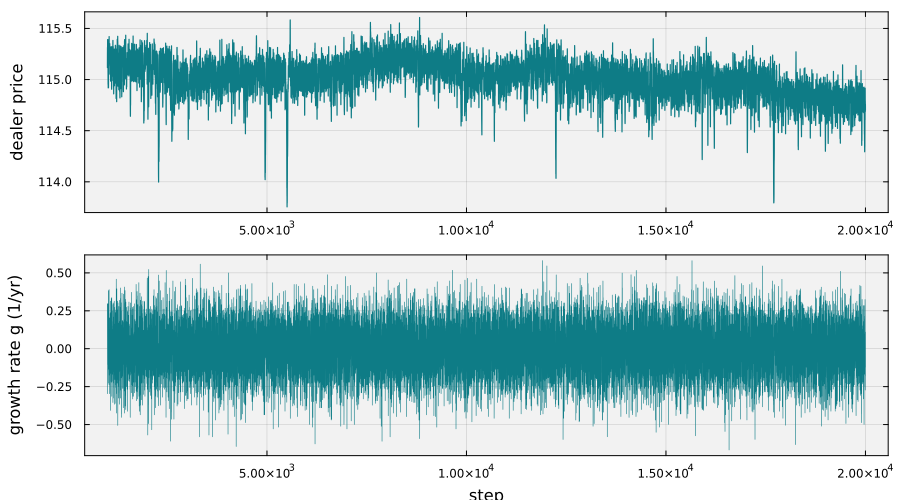

In [5]:
let

    # top panel: the dealer's price after the burn-in -
    t = burn_in .+ (0:(length(base.P) - 1));
    p1 = plot(t, base.P, c = color_wolfram, lw = 1.2, label = "", ylabel = "dealer price",
        bg = "gray95", background_color_outside = "white", framestyle = :box);

    # bottom panel: the growth rates -
    p2 = plot(t[2:end], base.g, c = color_wolfram, lw = 0.6, label = "", xlabel = "step", ylabel = "growth rate g (1/yr)",
        bg = "gray95", background_color_outside = "white", framestyle = :box);

    # show both panels -
    plot(p1, p2, layout = (2, 1), size = (900, 500), left_margin = 4Plots.mm)
end

Now the stylized facts. [The stylized_facts_report(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) returns the autocorrelations of $g$ and of $|g|$ at the chosen lags, the white-noise band, and the Hill tail index. We add the excess kurtosis from `src/Helper.jl`, which is zero for Normal growth rates:

In [6]:
base_facts = let

    # the stylized facts of the baseline market -
    report = stylized_facts_report(base.g; lags = lags);
    df = DataFrame(
        statistic = ["excess kurtosis"; ["autocorrelation of g, lag $(l)" for l ∈ lags]; ["autocorrelation of |g|, lag $(l)" for l ∈ lags];
            "white-noise band (±)"; "Hill tail index"],
        value = [excess_kurtosis(base.g); report.raw_acf; report.absolute_acf; report.white_noise_95_band; report.tail_index]
    );
    pretty_table(df; column_labels = ["statistic (Wolfram market)", "value"], alignment = [:l, :r], formatters = [fmt__printf("%.3f", [2])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert nrow(df) == 2 * length(lags) + 3 "one row for each statistic"

    # return -
    df
end;

 -------------------------------- --------
  statistic (Wolfram market)        value 
 -------------------------------- --------
  excess kurtosis                   0.016
  autocorrelation of g, lag 1       0.133
  autocorrelation of g, lag 5      -0.066
  autocorrelation of g, lag 20     -0.002
  autocorrelation of |g|, lag 1     0.035
  autocorrelation of |g|, lag 5     0.012
  autocorrelation of |g|, lag 20    0.004
  white-noise band (±)              0.014
  Hill tail index                   9.114
 -------------------------------- --------


> __What do we see?__
>
> * __Tails close to Normal:__ The excess kurtosis is 0.016, essentially that of Normal growth rates.
> * __Autocorrelated growth rates:__ The lag-1 autocorrelation of $g$ is 0.133, far outside the white-noise band of ±0.014.
> * __Weak, short-lived clustering:__ The autocorrelation of $|g|$ is 0.035 at lag 1, small but outside the band. It is inside the band by lag 5.

A switched market's price trends through the cascade, and its growth rates are then not stationary. The same statistics measure the trend more than the market. Let's compute them for a switched market and its control, after the switch:

In [7]:
let

    # run a switched market and its control with the same seed, switching halfway -
    pair = WM.run_rule_switch(L = L, f = 0.25, h = h_deep, seed = seed, boundary_mode = :endogenous, t_pre = steps ÷ 2, t_post = steps ÷ 2);

    # growth rates after the switch for each arm, and their statistics -
    rows = NamedTuple[];
    for (name, arm) ∈ (("switched", pair.switched), ("control", pair.control))
        g = (1/Δt) .* diff(log.(arm.prices[(pair.t_pre + 1):end]));
        report = stylized_facts_report(g; lags = [1]);
        push!(rows, (market = name, kurtosis = excess_kurtosis(g), acf1 = report.raw_acf[1], abs_acf1 = report.absolute_acf[1],
            sell_last = arm.sell_fraction[end]));
    end
    pretty_table(DataFrame(rows); column_labels = ["market", "excess kurtosis", "autocorrelation of g, lag 1", "autocorrelation of |g|, lag 1", "last-step Sell fraction"],
        alignment = [:l, :r, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert pair.switched.prices[1:(pair.t_pre + 1)] == pair.control.prices[1:(pair.t_pre + 1)] "the arms share their history"

    # return -
    nothing
end

 ---------- ----------------- ----------------------------- ------------------------------- -------------------------
  market     excess kurtosis   autocorrelation of g, lag 1   autocorrelation of |g|, lag 1   last-step Sell fraction 
 ---------- ----------------- ----------------------------- ------------------------------- -------------------------
  switched             1.575                        -0.336                           0.613                     0.823
  control             -0.051                         0.140                           0.044                     0.254
 ---------- ----------------- ----------------------------- ------------------------------- -------------------------


> __What do we see?__
>
> * __The switched market:__ After the switch, its excess kurtosis is 1.575 and the lag-1 autocorrelation of $|g|$ is 0.613, against −0.051 and 0.044 for its control. Its Sell fraction ends at 0.823, against 0.254 for the control.
> * __Why we use the baseline:__ These numbers measure the cascade, a change in the market itself, rather than the statistics of a steady market. The rest of this example uses markets that never switch.

___

## Task 2: Compare with a Real Ticker and with Farmer–Joshi
In this task, we put the Wolfram market beside the daily growth rates of a real ticker and the Farmer–Joshi market with both groups of traders from L12a. Each series has its own white-noise band, because the band shrinks as the number of growth rates grows.

[The MyFarmerJoshiMarketModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) builds the L12a market, and `solve(...)` runs it:

In [8]:
compare_df = let

    # the real ticker: daily growth rates (1/yr) -
    prices = dataset[ticker].close;
    g_ticker = (1/Δt) .* diff(log.(prices));

    # the Farmer–Joshi market with both groups of traders, as in L12a -
    rng = MersenneTwister(fj_seed);
    model = build(MyFarmerJoshiMarketModel, (σ_S = σ_S, σ_v = σ_v, Δt = Δt, rng = rng));
    g_fj = solve(model; number_of_steps = fj_steps, burn_in = fj_burn_in, rng = rng).returns ./ Δt;

    # the same statistics for the three series -
    series = [("Wolfram market", base.g), (ticker, g_ticker), ("Farmer–Joshi", g_fj)];
    df = DataFrame(statistic = ["excess kurtosis"; ["autocorrelation of g, lag $(l)" for l ∈ lags]; ["autocorrelation of |g|, lag $(l)" for l ∈ lags]; "white-noise band (±)"]);
    for (name, g) ∈ series
        r = stylized_facts_report(g; lags = lags); # autocorrelations and white-noise band of this series
        df[!, name] = [excess_kurtosis(g); r.raw_acf; r.absolute_acf; r.white_noise_95_band];
    end
    println("growth rates: ", join(["$(name) $(length(g))" for (name, g) ∈ series], ", "));
    pretty_table(df; column_labels = names(df), alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert all(isfinite, Matrix(df[:, 2:end])) "every statistic is finite"

    # return -
    (df = df, series = series)
end;

growth rates: Wolfram market 19000, SPY 2766, Farmer–Joshi 20000
 -------------------------------- ---------------- -------- --------------
  statistic                        Wolfram market      SPY   Farmer–Joshi 
 -------------------------------- ---------------- -------- --------------
  excess kurtosis                           0.016   13.768         68.888
  autocorrelation of g, lag 1               0.133   -0.110          0.173
  autocorrelation of g, lag 5              -0.066    0.040          0.120
  autocorrelation of g, lag 20             -0.002   -0.016          0.044
  autocorrelation of |g|, lag 1             0.035    0.364          0.801
  autocorrelation of |g|, lag 5             0.012    0.325          0.190
  autocorrelation of |g|, lag 20            0.004    0.194         -0.045
  white-noise band (±)                      0.014    0.037          0.014
 -------------------------------- ---------------- -------- --------------


Let's plot the autocorrelations of $g$ and of $|g|$ for the three series at lags 1 to 50:

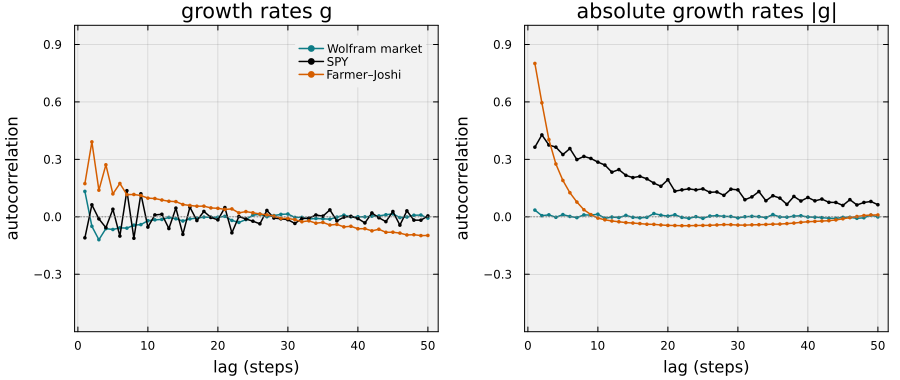

In [9]:
let

    # initialize: lags, colors, and one panel for g and one for |g| -
    all_lags = collect(1:50);
    colors = [color_wolfram, color_ticker, color_fj];
    panels = [];
    for (k, title_text) ∈ ((1, "growth rates g"), (2, "absolute growth rates |g|"))
        q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, title = title_text, ylims = (-0.6, 1.0),
            xlabel = "lag (steps)", ylabel = "autocorrelation", legend = (k == 1 ? :topright : false), fg_legend = :transparent);
        for ((name, g), c) ∈ zip(compare_df.series, colors)
            x = (k == 1 ? g : abs.(g));
            plot!(q, all_lags, sample_autocorrelation(x, all_lags), c = c, lw = 1.5, marker = :circle, ms = 2, msw = 0, label = name);
        end
        hline!(q, [0.0], c = :gray, ls = :dot, label = "");
        push!(panels, q);
    end

    # show the two panels side by side -
    plot(panels..., layout = (1, 2), size = (900, 380), bottom_margin = 4Plots.mm, left_margin = 4Plots.mm)
end

> __What do we see?__
>
> * __Fat tails:__ The excess kurtosis is 13.768 for SPY and 68.888 for Farmer–Joshi, against 0.016 for the Wolfram market. Only the Wolfram market has tails close to Normal.
> * __Volatility clustering:__ The lag-1 autocorrelation of $|g|$ is 0.364 for SPY and 0.801 for Farmer–Joshi, against 0.035 for the Wolfram market. SPY's is still 0.194 at lag 20, far above its band of ±0.037, while the Wolfram market's has faded into its band.
> * __Autocorrelation of $g$:__ At lag 1, it is 0.133 for the Wolfram market, 0.173 for Farmer–Joshi, and −0.110 for SPY. The Farmer–Joshi numbers differ from the L12a table because we build its market from a fresh random stream, which gives different traders and different random moves.

___

## Task 3: Does Feedback Create the Facts?
In this task, we vary the two features that shape the loop from price to traders: the edge traders and the dealer's depth. Active edge traders read the dealer's price, held ones never do, and random ones draw Buy, Hold, or Sell at random. A shallow dealer moves the price further for each net order.

We run each condition for several starting markets and average the statistics:

In [10]:
feedback_df = let

    # initialize: the conditions (edge traders, dealer depth, name) -
    conditions = [(:endogenous, h_deep, "deep dealer, active edge"), (:hold, h_deep, "deep dealer, held edge"),
        (:random, h_deep, "deep dealer, random edge"), (:endogenous, h_shallow, "shallow dealer, active edge")];
    rows = NamedTuple[];

    # main loop: one baseline market for each condition and seed -
    t_total = @elapsed for (mode, h, name) ∈ conditions, sd ∈ seeds
        r = run_baseline(L = L, h = h, boundary_mode = mode, seed = sd, steps = steps);
        g = (1/Δt) .* diff(log.(r.prices[(burn_in + 1):end]));
        report = stylized_facts_report(g; lags = [1]);
        push!(rows, (condition = name, seed = sd, kurtosis = excess_kurtosis(g), acf1 = report.raw_acf[1], abs_acf1 = report.absolute_acf[1]));
    end

    # average over the seeds, in the order of the conditions -
    df = DataFrame(rows);
    means = combine(groupby(df, :condition, sort = false), :kurtosis => mean => :kurtosis, :acf1 => mean => :acf1, :abs_acf1 => mean => :abs_acf1);
    println("run time: $(round(t_total; digits = 1)) seconds; $(length(seeds)) starting markets per condition; white-noise band ±$(round(1.96/sqrt(steps - burn_in); digits = 3))");
    pretty_table(means; column_labels = ["condition", "excess kurtosis", "autocorrelation of g, lag 1", "autocorrelation of |g|, lag 1"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert nrow(df) == length(conditions) * length(seeds) "one row for each condition and seed"

    # return -
    df
end;

run time: 5.4 seconds; 3 starting markets per condition; white-noise band ±0.014
 ----------------------------- ----------------- ----------------------------- -------------------------------
  condition                     excess kurtosis   autocorrelation of g, lag 1   autocorrelation of |g|, lag 1 
 ----------------------------- ----------------- ----------------------------- -------------------------------
  deep dealer, active edge                0.012                         0.115                           0.029
  deep dealer, held edge                 -0.000                         0.336                           0.110
  deep dealer, random edge                0.004                         0.345                           0.112
  shallow dealer, active edge             0.039                        -0.592                           0.375
 ----------------------------- ----------------- ----------------------------- -------------------------------


> __What do we see?__
>
> * __No condition creates fat tails:__ The three-seed mean of the excess kurtosis stays between −0.000 and 0.039 in every condition. In these runs, neither price feedback nor a shallow dealer gives the Wolfram market fat tails.
> * __Feedback damps the autocorrelation of $g$:__ With a deep dealer, the lag-1 autocorrelation of $g$ is 0.115 with active edge traders, against 0.336 held and 0.345 random. The held and random edges, which both ignore the price, give almost the same statistics.
> * __A shallow dealer reverses it:__ The lag-1 autocorrelation of $g$ is −0.592, and that of $|g|$ rises to 0.375. SPY's lag-1 autocorrelation of $g$ is also negative, −0.110, but much weaker.

___

## Summary
In this example, we measured the stylized facts of a Wolfram market's price, compared them with a real ticker and the Farmer–Joshi market, and varied the loop from price to traders.

> __Key Takeaways:__
>
> * __A model price can be measured like a real one:__ We computed the growth rates of the dealer's price in a Wolfram market that never switches, and measured their tails and autocorrelations. Its growth rates have tails close to Normal, a positive lag-1 autocorrelation, and only weak, short-lived clustering.
> * __The Wolfram market does not look like a real market:__ We put its statistics beside SPY and the Farmer–Joshi market, which both show fat tails and volatility clustering. The Wolfram market shows no fat tails and little clustering, because it was built to study rule switches, not price statistics.
> * __Feedback changes the autocorrelations, not the tails:__ We compared active, held, and random edge traders and a deep and a shallow dealer. Price feedback damped the autocorrelation of the growth rates and a shallow dealer reversed it, but no condition produced fat tails in these runs.

A model built to answer one question can fail another, and measuring both is how we learn what a model is for.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___